# Cross-tissue Differential expression analysis
1. [Cross-tissue DE analysis in each cell type](#section1)
2. [Examine the functions of lung and spleen DE genes](#section2)

In [1]:
## Load package and the seurat object
library(Seurat)
library(data.table)
library(dplyr)
library(ggplot2)
library(plotly)
library(patchwork)
library(clusterProfiler)
library(org.Hs.eg.db)
library(enrichplot)
library(GOSemSim)
library(gridExtra)
library(slingshot)
source("code/make_plots.R")
options(repr.plot.width=14, repr.plot.height=10)

dataDIR <- "output"
pal_atac <- readRDS("data/color_codes.RDS")
pal_rna <- pal_atac

Attaching SeuratObject

Seurat v4 was just loaded with SeuratObject v5; disabling v5 assays and
validation routines, and ensuring assays work in strict v3/v4
compatibility mode


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout




clusterProfiler v4.6.2  For help: https://yulab-smu.top/biomedical-knowledge-mining-book/

If you use clusterProfiler in published research, please cite:
T Wu, E Hu, S Xu, M Chen, P Guo, Z Dai, T Feng, L Zhou, W Tang, L Zhan, X Fu, S Liu, X Bo, and G Yu. clusterProfiler 4.0: A universal enr

<a id='section4'></a>

## 1. Cross-tissue DE analysis in each cell type 

We performed differential gene expression between tissue with pseudo-bulk samples using DESeq2 (v1.38.3) (Love, Huber, and Anders, 2014). The test was done on the RNA count matrix aggregated by donor, tissue and cell types using Seurat::AggregateExpression. We also adjusted
for covariates including batch, ethnicity, age, and sex. Due to low number of cells in CD4 T subsets in spleen, we excluded regulatory T cells and combined naive and memory CD4 T cells for cross-tissue comparison.

In [5]:
# Merge CD4 T cell subsets (Treg excluded)
immune.combined$MainCellType <- 
    factor(immune.combined$CellType,
           labels = c("Other",
                      "Treg",
                      "CD4_T",
                      "CD4_T",
                      "CD8_T",
                      "NK",
                      "Memory_B",
                      "Naive_B"))

Loading required package: Signac

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode



In [4]:
# Prepare aggregated RNA count matrix
sample_cov <- fread("../../data/sample_covariates.txt")
colnames(sample_cov)[3] <- "library_id"

# Match by sample ID
metadata <- data.frame(
    library_id = c(paste("SMO", c(2,3,5,7,8,9), sep = "-"),
                   paste("SMO", c(1,4,10), sep = "-")),
    full.ident = c(paste("lungs", 1:6, sep = "_"),
                   paste("spleens", 1:3, sep = "_")))
metadata <- left_join(sample_cov[, 1:8], metadata, by = "library_id")
row_names <- rownames(immune.combined@meta.data)
immune.combined@meta.data <- left_join(immune.combined@meta.data, metadata)
rownames(immune.combined@meta.data) <- row_names

Joining with `by = join_by(full.ident)`


In [ ]:
# Prepare gene by cell matrix for RNA counts
cell_barcodes <- unlist(lapply(rownames(immune.combined@meta.data), function(i){strsplit(i, "_")[[1]][1]}))
cell_barcodes <- paste(immune.combined@meta.data$library_id, cell_barcodes, sep = "_")

rna_matrix <- immune.combined@assays$RNA@counts
colnames(rna_matrix) <- cell_barcodes

write.csv(as.matrix(rna_matrix), gzfile("/project/xinhe/jinggu/projects/u19_multiomics/peak2gene/scE2G/resources/u19_multiome/rna_count_matrix.csv.gz"),
         row.names = TRUE, quote = F)

In [39]:
## Group cells into pseudobulk by donor, tissue and cell types
pseudo_rna <- AggregateExpression(immune.combined, return.seurat = T, 
                                  assays = "RNA", slot = "counts",
                                  group.by = c("library_id", "MainCellType"))

row_names <- rownames(pseudo_rna@meta.data)
pseudo_rna@meta.data <- 
    left_join(pseudo_rna@meta.data %>%
               mutate(rowNames = row_names), 
              immune.combined@meta.data %>% 
                  mutate(rowNames = paste(library_id, MainCellType, sep = "_")) %>%
                  dplyr::select(rowNames, full.ident, MainCellType, library_id, ROBI, cells, submission_date, Age, Sex, Race,`Asthmatic status`) %>%
                  distinct()
              )

# Add rownames to metadata is necessary for seurat function to work.
rownames(pseudo_rna@meta.data) <- row_names
#colnames(pseudo_rna@meta.data)[11] <-"Asthmatic_status"

Centering and scaling data matrix

Joining with `by = join_by(rowNames)`


In [76]:
## Perform cross-tissue DE analysis one cell type at a time with DESeq2

library(DESeq2)
DEG_list <-
    lapply(unique(pseudo_rna@meta.data$MainCellType), function(i) {
        sub_rna = subset(pseudo_rna, MainCellType == i)
        dds <- DESeqDataSetFromMatrix(countData = sub_rna@assays$RNA@counts, 
                                  colData = sub_rna@meta.data,
                                  design = ~ factor(submission_date) + Race + Age + Sex + cells) #Age as numeric
        dds <- DESeq(dds, betaPrior = FALSE)
        mm <- model.matrix(design(dds), colData(dds))
        qr(mm)$rank
        ncol(mm)
        print(qr(mm)$rank == ncol(mm))
        res <- results(dds, contrast = c("cells", "Lung", "Spleen"))
        return(res)
        })

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] TRUE


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] TRUE


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

...

[1] TRUE


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] TRUE


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] TRUE


In [78]:
names(DEG_list) <- unique(pseudo_rna@meta.data$MainCellType)
DEG_list <- lapply(names(DEG_list), function(i) {
  data.frame(DEG_list[[i]], cluster = gsub("-", "_", i)) %>%
    mutate(gene = rownames(DEG_list[[i]])) %>%
    filter(!is.na(log2FoldChange))
})

DEG_tbl <- do.call(rbind, DEG_list)

In [ ]:
names(DEG_list) <- unique(pseudo_rna@meta.data$MainCellType)
saveRDS(DEG_list, "../../output/output_dir/remove_dup/cross-tissue_DE/bulk_cross-tissue_DESeq2.RDS")
saveRDS(pseudo_rna@assays$RNA@counts, "../../output/output_dir/remove_dup/pseudobulk_RNA_counts.RDS")

In [94]:
ct_order <- c("Naive_B", "Memory_B", 'NK','CD8_T','CD4_T','Treg', 'Other')

In [201]:
## Summarize number of DE genes into a table
DEG_counts <-
    lapply(DEG_list, function(i) {
        data.frame(i) %>% filter(padj <= 0.05) %>% 
            mutate(
                Category = 
                case_when(log2FoldChange > 0.58 ~ "lung-up",
                          log2FoldChange < -0.58 ~ "spleen-up")) %>%
            group_by(Category) %>% dplyr::summarise(n = n())
    })

In [202]:
do.call(rbind, DEG_counts) %>% filter(!is.na(Category)) %>% 
    mutate(CellType = unlist(lapply(names(DEG_list), function(i){rep(i, 2)})))

Category,n,CellType
<chr>,<int>,<chr>
lung-up,35,Other
spleen-up,3,Other
lung-up,60,Treg
spleen-up,9,Treg
lung-up,226,CD4_T
spleen-up,102,CD4_T
lung-up,100,CD8_T
spleen-up,70,CD8_T
lung-up,63,NK


### Visualize DE results with volcano plots

In [ ]:
## Load cross-tissue DE list
#DEG_list <- readRDS("output/u19_multiomics/output/u19_rna/bulk_cross-tissue_DESeq2.RDS")
DEG_list <- lapply(names(DEG_list), function(i) {
  data.frame(DEG_list[[i]], cluster = gsub("-", "_", i)) %>%
    filter(!is.na(log2FoldChange))
})

## Make a table of DE genes grouped by effect direction 
DGE_tbl <- do.call(rbind, DEG_list)

gginput <-
    DGE_tbl %>% 
      mutate(avg_log2FC = log2FoldChange) %>%
      filter(cluster != "Other" & padj <= 0.05) %>%
      mutate(group = case_when(avg_log2FC >= 1~ "Lung Up-regulated", 
                                 avg_log2FC <= -1 ~ "Spleen Up-regulated")) 
## Summarize total number of DE genes
totalCounts <- gginput %>% group_by(cluster) %>% dplyr::summarise(n = n())

In [ ]:
## Make a combined volcano plot for DE genes in each cell type
library(ggrepel)
selected <- ct_order[1:5]
gginput <- left_join(totalCounts, gginput, by = "cluster")
gginput$label <- sprintf("%s (%s)", gginput$cluster, gginput$n)
panel_order <-
  unlist(lapply(ct_order[1:5], function(i){levels(factor(gginput$label))[grep(i, levels(factor(gginput$label)))]}))
p1 <-
ggplot(
  gginput %>% filter(cluster %in% selected),
  aes(
    x = avg_log2FC ,
    y = -log10(pvalue),
    color = cluster,
  )
) +
  geom_point(size = 0.5) +
  scale_color_manual(values = c(pal_rna)) + 
  geom_point(
    data =
      gginput %>% 
      filter(padj > 0.05) %>%
      filter(cluster %in% selected),
    aes(x = avg_log2FC, y = -log10(pvalue)),
    color = alpha("grey", 0.7),
    size = 0.5
  ) +
  geom_text_repel(
    data = gginput %>% filter(cluster %in% selected),
    aes(label = ifelse(abs(avg_log2FC) >= 0.58, gene, "")),
    color = "grey30",
    #max.overlaps = 15,
    nudge_x = 0.1, nudge_y = 0.1,
    size = 2) +
  facet_wrap(~ factor(label, levels = panel_order), nrow = 2) +
  theme_pub() + 
  ylab("-log10(p-value)") + #xlim(c(-5, 10)) + 
  theme(legend.position = "none")

### One example, *GNLY*, with large gene expression differences between tissue

In [81]:
DEG_tbl <- do.call(rbind, DEG_list)
DEG_tbl %>% filter(gene == "GNLY")

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
GNLY,12.648198,2.972263,1.6225161,1.831885,6.696855e-02,3.850691e-01,Other,GNLY
GNLY1,6.912048,2.335298,1.4012816,1.666545,9.560501e-02,3.396096e-01,Treg,GNLY
GNLY2,99.596412,3.096007,1.1867872,2.608730,9.087894e-03,1.183829e-01,CD4_T,GNLY
GNLY3,703.314731,2.215558,1.1537303,1.920343,5.481458e-02,3.279205e-01,CD8_T,GNLY
GNLY4,1599.098355,1.875657,0.6155734,3.047007,2.311320e-03,4.895168e-02,NK,GNLY
GNLY5,162.494737,6.327376,1.3000249,4.867119,1.132367e-06,1.237137e-04,Memory_B,GNLY
GNLY6,32.300481,7.214666,1.2406112,5.815413,6.048451e-09,2.793661e-06,Naive_B,GNLY


In [10]:
# aggregate RNA counts by library_id 
metadata <- data.frame(
    library_id = c(paste("SMO", c(2,3,5,7,8,9), sep = "-"),
                   paste("SMO", c(1,4,10), sep = "-")),
    full.ident = c(paste("lungs", 1:6, sep = "_"),
                   paste("spleens", 1:3, sep = "_")))

immune.combined@meta.data$library_id <- left_join(immune.combined@meta.data, metadata) %>% pull(library_id)
immune.combined@meta.data$CellGroup <- paste(immune.combined$library_id, immune.combined$CellType, sep = "-")
pb <- AggregateExpression(
  object = immune.combined,
  group.by = "CellGroup",
  assays = "RNA",
  slot = "counts"
)

Joining with `by = join_by(full.ident)`
Names of identity class contain underscores ('_'), replacing with dashes ('-')
This message is displayed once every 8 hours.


In [126]:
immune.combined$MainCellType <- factor(immune.combined$MainCellType, levels = ct_order)
p1 <- VlnPlot(subset(immune.combined, MainCellType != "Other"), features = "GNLY", pt.size = 0, group.by = "MainCellType", split.by = "tissue.ident") + 
theme_pub(base_size = 15) 

Warning message in SingleExIPlot(type = type, data = data[, x, drop = FALSE], idents = idents, :
“All cells have the same value of GNLY.”
Warning message in max(data[, feature][is.finite(x = data[, feature])]):
“no non-missing arguments to max; returning -Inf”
Warning message in min(data[, feature]):
“no non-missing arguments to min; returning Inf”


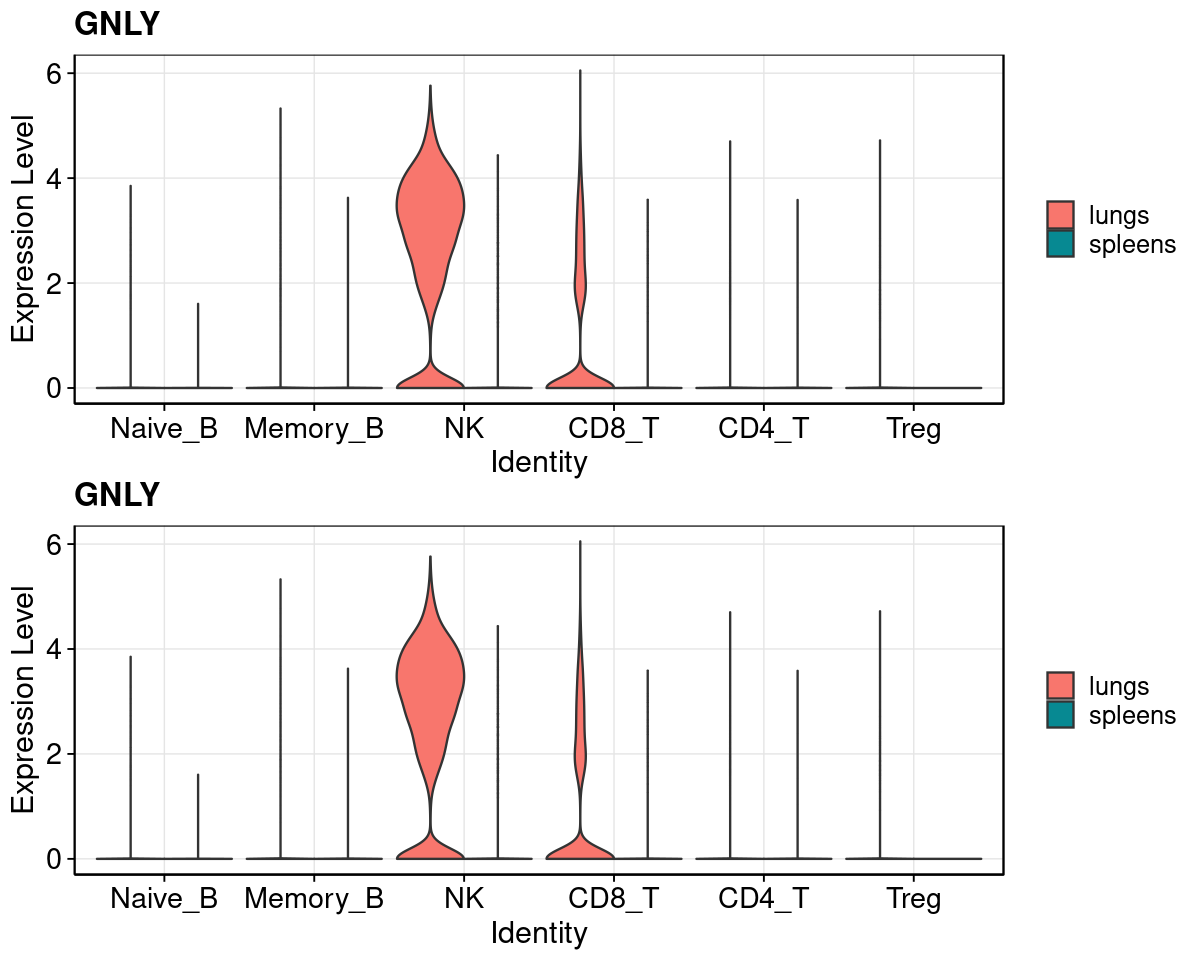

In [15]:
options(repr.plot.width=10, repr.plot.height=8)
p1 + p1

<a id='section5'></a>

## 2. Examine the functions of lung or spleen DE genes 

We performed GO enrichment test for DE genes one cell type at at time separately for each tissue.

In [ ]:
## Prepare inputs for GO enrichment
bkgGenes <- unique(tests$Other$gene)
lung_up <- gginput[gginput$group == "Lung Up-regulated", ]
genesets <- lapply(split(lung_up, lung_up$cluster), function(i) {i$gene})
spleen_up <- gginput[gginput$group == "Spleen Up-regulated", ]
genesets <- lapply(split(spleen_up, spleen_up$cluster), function(i) {i$gene})

In [ ]:
## Bash 
Rscript --vanilla code/run_GO_enrichment.R --geneset lung_up.RDS --bkg genesets.RDS --out lung_upreg
Rscript --vanilla code/run_GO_enrichment.R --geneset spleen_up.RDS --bkg genesets.RDS --out spleen_upreg

In [ ]:
## Visulize GO enrichment outputs
go_list <- readRDS("lung_upreg_GO_enrichment.RDS")
feature = "Biological"
go_tbl <-
  do.call(rbind, go_list) %>%
    filter(k %in% ct_order[1:5])
write.table(go_tbl %>% filter(FDR <= 0.05 & grepl("Biological", database)) %>% dplyr::select(-database), "tables/Enriched_GO_BP_lungUp.txt", quote = F, sep = "\t")
toshow <- 
    unique(
      go_tbl %>% 
        filter(FDR <= 0.05 & grepl(feature, database)) %>%
            group_by(k) %>%
            slice_max(n = 7, order_by = enrichmentRatio) %>%
            pull(description))
p2 <-
ggplot(
    go_tbl %>% 
      filter(grepl(feature, database) & description %in% toshow & 
               FDR <= 0.05) %>%
      mutate(FDR = ifelse(FDR == 0, 10^(-10), FDR),
             Enrichment = enrichmentRatio),
    aes(y = description,
        x = factor(k, levels = ct_order[1:5]),
        size = Enrichment,
        color = -log10(FDR))) + 
    geom_point() + xlab("") + ylab("") + 
     # scale_fill_gradient(
     #   limits = c(0, 4),
     #   oob = squish) +
    theme_pub() + #ggtitle("GO BP enrichment for lung up-regulated genes") 
    theme(axis.text.x = element_text(angle = 45, vjust = 0.5),
          axis.text.y = element_text(),
          legend.position = "bottom")
p2

In [ ]:
go_list <- readRDS("spleen_upreg_GO_enrichment.RDS")
feature = "Biological"
go_tbl <-
  do.call(rbind, go_list) %>%
    filter(k %in% ct_order[1:5])
write.table(go_tbl %>% filter(FDR <= 0.1 & grepl("Biological", database)) %>% dplyr::select(-database), "tables/Enriched_GO_BP_spleenUp.txt", quote = F, sep = "\t")

toshow <- 
    go_tbl %>% 
      filter(FDR <= 0.1 & grepl(feature, database)) %>%
          group_by(k) %>%
          pull(description)

ggplot(
    go_tbl %>% 
      filter(grepl(feature, database) & description %in% toshow),
    aes(y = description,
        x = factor(k, levels = ct_order[1:5]),
        size = enrichmentRatio,
        color = -log10(FDR_adj))) + 
    geom_point() + xlab("") + ylab("") + 
    theme_pub() + ggtitle("GO BP enrichment for spleen up-regulated genes") 